# Schiphol approach viewer

**Run All**, then choose a flight below. If VS Code asks for a kernel, select **Airplanes practice (.venv)**.

Green = prediction snapshot; orange = threshold-crossing estimate. The solid blue path is observed history and the dashed orange path is future data used to check the label. All times are UTC.

The training table is **unsplit**. One row = one accepted approach to runway 18R. Labels estimate threshold crossing, before touchdown.

In [1]:
%matplotlib inline
from pathlib import Path
import sys, json
from IPython.display import display, HTML

ROOT = next((candidate for p in [Path.cwd(), *Path.cwd().parents]
             for candidate in (p, p / 'data_preprocessing')
             if (candidate / 'prepared' / 'training.csv').exists()
             and (candidate / 'src' / 'approach').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Open this project folder in VS Code and run prepare_data.py first.')
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))

from approach.notebook import load_prepared, flight_selector, show_flight
training, labels, tracks, runways, schema = load_prepared(ROOT)
summary = json.loads((ROOT / 'prepared' / 'dataset_summary.json').read_text())
print(f"{len(training)} accepted approaches · {summary['rejected_approaches']} rejected · Schiphol 18R · unsplit")

194 accepted approaches · 166 rejected · Schiphol 18R · unsplit


## Choose a flight
The right-hand map enlarges the actual landing threshold, 270 metres inside the pavement's northern end.

In [2]:
selector = flight_selector(training, labels, tracks, runways)

Dropdown(description='Flight:', layout=Layout(width='520px'), options=(('TRA64V · 00:34:04 UTC', 'EHAM18R_4851…

Output()

## Your training table

This is the small file to split later: `prepared/training.csv`.

Use the feature list in `schema.json`. Aircraft identifiers, callsigns and timestamps are metadata; `labels_audit.csv` and `tracks.csv.gz` contain future observations and must stay out of model inputs.

In [3]:
display(training[['callsign', 'snapshot_time_utc', 'distance_to_threshold_m',
                  'groundspeed_mps', 'remaining_time_s']].head(8).round(2))

# Ready for your later split and model. No split or model fitting happens here.
FEATURE_COLUMNS = schema['feature_columns']
X = training[FEATURE_COLUMNS].copy()
y = training[schema['target_column']].copy()
flight_groups = training[schema['group_column']].copy()
print(f'X: {X.shape[0]} rows × {X.shape[1]} snapshot features; y: seconds to threshold')

,callsign,snapshot_time_utc,distance_to_threshold_m,groundspeed_mps,remaining_time_s
0,TRA64V,2023-03-15T00:34:04+00:00,13377.16,110.09,151.70
1,BCS15Q,2023-03-15T00:52:17+00:00,13721.83,103.92,170.13
2,BCS21G,2023-03-15T03:56:43+00:00,18161.90,95.69,232.23
3,FDX6235,2023-03-15T04:11:17+00:00,12763.78,100.83,168.98
4,DAL132,2023-03-15T04:15:06+00:00,13683.75,109.58,164.31
5,KLM588,2023-03-15T04:20:22+00:00,13851.40,92.60,170.09
6,KLM272,2023-03-15T04:34:14+00:00,13684.40,104.43,159.63
7,KLM280,2023-03-15T04:36:55+00:00,8248.90,96.20,98.38


X: 194 rows × 11 snapshot features; y: seconds to threshold


## Quick data check

Large differences from constant-speed ETA can be real deceleration, or a reason to inspect the flight. The source is only one date, and labels are interpolated from sampled ADS-B states.

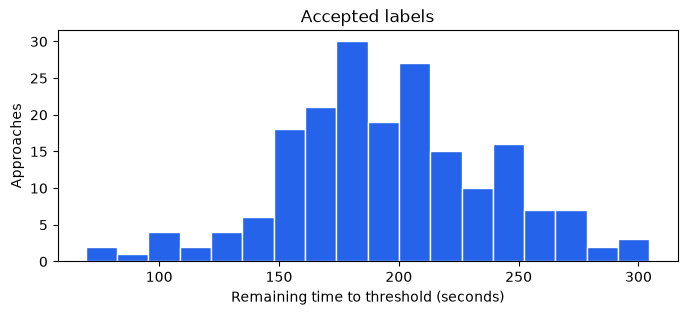

Median: 193.1 s; range: 69.4–304.6 s
Constant-speed baseline MAE: 31.0 s (no trained model)


In [4]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(y, bins=18, color='#2563eb', edgecolor='white')
ax.set(xlabel='Remaining time to threshold (seconds)', ylabel='Approaches', title='Accepted labels')
plt.show()
print(f'Median: {y.median():.1f} s; range: {y.min():.1f}–{y.max():.1f} s')
print(f'Constant-speed baseline MAE: {(training.baseline_eta_s - y).abs().mean():.1f} s (no trained model)')

## Share with your friend

For a simple browser view, double-click **prepared/viewer.html**. It has a flight selector, zoom, pan and a timeline.

**share/schiphol_18R_unsplit.zip** contains the viewer, training CSV and audit files. Extract the ZIP before opening the HTML. After you create `train.csv`, `validation.csv` and `test.csv`, use `make_share_package.py --split-dir <your folder>` to package those partitions instead.

Runway geometry is supported by primary charts before and after the recording date. The exact March 2023 AIP/NOTAM cycle and independent position freshness remain unverified; see `prepared/README.md`.